
Searching SIMBAD for 'M13'...
Coordinates found: RA 250.423°, Dec 36.461°
Processing successful. Plotting 3195 stars...



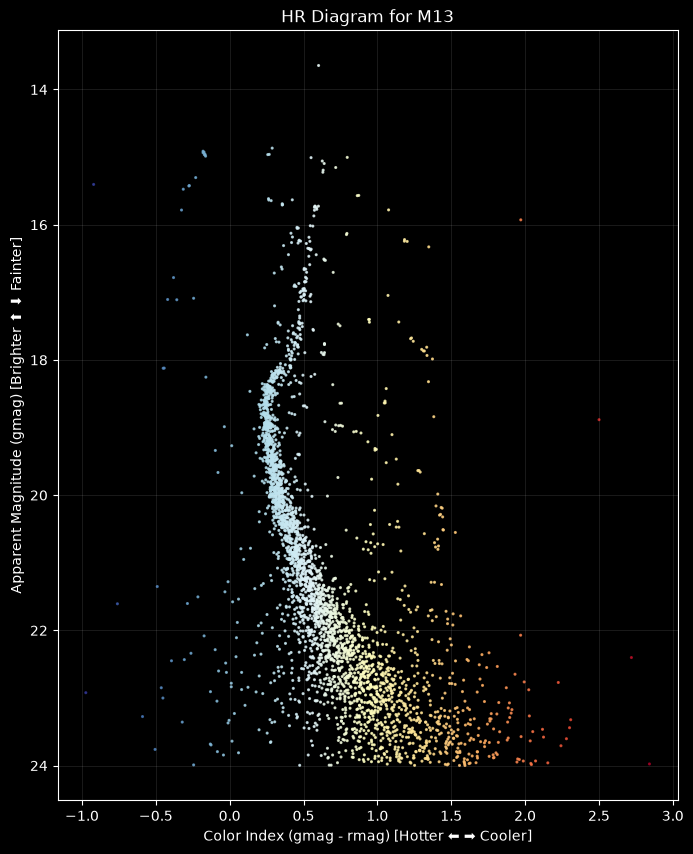

In [17]:
from astroquery.vizier import Vizier
import astropy.coordinates as coord
import astropy.units as u
import matplotlib.pyplot as plt
import warnings
from astropy.utils.exceptions import AstropyWarning

warnings.simplefilter('ignore', category=AstropyWarning)

# SETUP
## Get a target name
target_name = ""
while not target_name:
    target_name = input("Enter the name of a star cluster (e.g., M13, M67, NGC 2419): ").strip()
    if not target_name:
        print("Please enter a valid target name.")

## Get a valid numerical radius
search_radius = None
while search_radius is None:
    radius_input = input("Enter search radius in arcminutes: ").strip()
    try:
        search_radius = float(radius_input)
    except ValueError:
        print("Invalid input. Please enter a valid number.")

# RESOLVE COORDINATES & FETCH DATA
print(f"\nSearching SIMBAD for '{target_name}'...")
try:
    target = coord.SkyCoord.from_name(target_name)
    print(f"Coordinates found: RA {target.ra.deg:.3f}°, Dec {target.dec.deg:.3f}°")
except Exception as e:
    print(f"Error: Could not resolve the name '{target_name}'. Try again.")
    exit()

print(f"Downloading SDSS data from VizieR (Radius: {search_radius} arcmin)...")
v = Vizier(row_limit=50000)
result = v.query_region(target, radius=search_radius*u.arcmin, catalog='V/147/sdss12')

# DATA PROCESSING
if len(result) == 0:
    print(f"\nError: VizieR returned 0 stars.")
else:
    df = result[0].to_pandas()
    
    ## Calculate Color Index
    df['Color'] = df['gmag'] - df['rmag']

    ## Filter out bad data
    clean_df = df[(df['Color'] > -1.0) & (df['Color'] < 3.0)]
    clean_df = clean_df[(clean_df['gmag'] > 13.0) & (clean_df['gmag'] < 24.0)]
    print(f"Processing successful. Plotting {len(clean_df)} stars...\n")

    # PLOTTING
    plt.style.use('dark_background')
    fig, ax = plt.subplots(figsize=(8, 10))
    
    scatter = ax.scatter(
        clean_df['Color'], 
        clean_df['gmag'], 
        c=clean_df['Color'], 
        cmap='RdYlBu_r', 
        s=1.5,        
        alpha=0.8     
    )

    ax.invert_yaxis()
    ax.set_xlabel('Color Index (gmag - rmag) [Hotter ⬅️ ➡️ Cooler]')
    ax.set_ylabel('Apparent Magnitude (gmag) [Brighter ⬆️ ⬇️ Fainter]')
    
    ax.set_title(f'HR Diagram for {target_name}')
    ax.grid(True, linestyle='-', color='white', alpha=0.1)

    plt.show()